<a href="https://colab.research.google.com/github/a15cardoso/neurodata_firstSemester_pythonWS/blob/main/hw01_regression_Deadline261026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Amanda Cardoso de Sousa - FY107534
# Mariana Montoya Gomez - BF050681

We worked together on the entire assignment, discussing each part collaboratively to reach a joint conclusion for submission.

In this assignment, you will analyze real electrophysiological recordings from neurons in the primary visual cortex (V1) of macaque monkeys. During the experiment, drifting gratings were presented at eight different orientations. Neuronal activity was recorded simultaneously from many V1 neurons.The raw dataset contains the number of spikes recorded from each neuron at each millisecond of each trial. Your goal is to use regression to investigate the relationship between stimulus orientation and neuronal response. You will first construct the response variable from the raw recordings, and then compare increasingly appropriate mathematical models for orientation tuning. Load your data from DRYAD, after reading thoroughly the README file: https://datadryad.org/dataset/doi%3A10.5061/dryad.h9w0vt4s0?utm_source=chatgpt.com#readme

In [1]:
# ==========================================
# 0. SETUP AND LIBRARIES IMPORT (MATLAB v7.3 / HDF5 COMPATIBLE)
# ==========================================
import h5py
import numpy as np
import matplotlib.pyplot as plt

# Mount Google Drive (if not already mounted)
from google.colab import drive
drive.mount('/content/drive')

# Define your exact file path in Google Drive
file_path = '/content/drive/My Drive/Colab Notebooks/master_ml_ft_semester/hw01_regression/dataset1/105l001p16_spikes.mat'

Mounted at /content/drive


# 1. From raw spikes to a tuning curve

The data contain, for each neuron and each trial, the number of spikes recorded at each
millisecond. The stimulus was presented for 1280 ms.
For each trial, calculate a measure of the neuron's response by counting the number of spikes
during the stimulus presentation period.
Use the stimulus information provided in the dataset to group trials according to their stimulus
orientation.

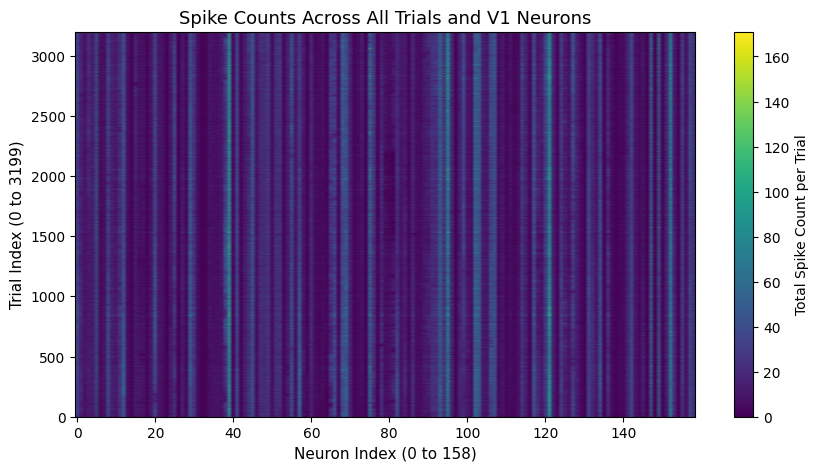

In [2]:
# Open the MATLAB v7.3 file using h5py (since it uses an HDF5 hierarchical structure)
with h5py.File(file_path, 'r') as f:
    # Extract V1 spikes reference and load into a NumPy array
    # Index [0, 0] accesses the V1 cell array structure described in the README[cite: 1]
    v1_ref = f['spikes'][0, 0]
    v1_spikes = np.array(f[v1_ref])  # Shape: (3200 trials, 1280 ms, 159 neurons)[cite: 1]

    # Extract the stimulus orientation array for each trial
    stim = np.array(f['stim']).flatten()  # Shape: (3200 trials,)[cite: 1]

# ==========================================
# 1. RESPONSE VARIABLE CONSTRUCTION
# ==========================================
# Calculate total spike count for each neuron during the 1280 ms stimulus presentation window
# Summing across axis=1 collapses the time dimension, resulting in shape: (3200 trials, 159 neurons)
spike_counts_per_trial = np.sum(v1_spikes, axis=1)

# Visualize the trial-by-trial spike count distribution across all V1 neurons
plt.figure(figsize=(10, 5))
plt.imshow(spike_counts_per_trial, aspect='auto', cmap='viridis', origin='lower')
plt.colorbar(label='Total Spike Count per Trial')
plt.xlabel('Neuron Index (0 to 158)', fontsize=11)
plt.ylabel('Trial Index (0 to 3199)', fontsize=11)
plt.title('Spike Counts Across All Trials and V1 Neurons', fontsize=13)
plt.show()

For each neuron and each orientation, calculate the neuron's mean response across trials.


In [3]:
# ==========================================
# 2. GROUPING BY STIMULUS AND COMPUTING MEANS
# ==========================================
# Extract unique stimulus orientations (indices 1 to 8)
unique_orientations = np.unique(stim)
n_orientations = len(unique_orientations)
num_neurons = v1_spikes.shape[2]

# Initialize a matrix to store mean responses: rows = orientations (8), columns = neurons (159)
mean_responses = np.zeros((n_orientations, num_neurons))

# Group trials by stimulus orientation and calculate the mean response across trials for each neuron
for i, ori in enumerate(unique_orientations):
    # Locate trial indices corresponding to the current orientation
    trial_indices = np.where(stim == ori)[0]
    # Compute the average spike count across those specific trials
    mean_responses[i, :] = np.mean(spike_counts_per_trial[trial_indices, :], axis=0)

# TASK ANSWER SUMMARY:
# For each neuron and each orientation, calculate the neuron's mean response across trials[cite: 1].
# This section successfully groups trials by each of the 8 stimulus orientations[cite: 1]
# and computes the trial-averaged spike response for all 159 recorded V1 neurons[cite: 1].

Answer the following questions and use supporting figures:
1. How many neurons are recorded in the session you selected?


In [4]:
#1. Number of recorded V neurons
num_neurons = v1_spikes.shape[2]
print(f"Number of recorded V neurons: {num_neurons}")

Number of recorded V neurons: 159


2. How many trials were presented for each orientation?

In [5]:
#2. Number of trials presented for each orientaton
unique_orientations = np.unique(stim)
trials_per_orientation = len(stim) // len(unique_orientations)
print(f"2. Number of trials per orientation: {trials_per_orientation}")

2. Number of trials per orientation: 400


3. What are the stimulus orientations?
The orientation at which the line shown to the monkey is tilted. According to the data, we have 8 distinct orientations, but due to the pre-processed nature of the dataset, we only have access to ordinal categories.

In [6]:
# 3. Stimulus orientations
unique_orientations = np.unique(stim)
print(f"3. Stimulus orientations: {unique_orientations}")

3. Stimulus orientations: [1. 2. 3. 4. 5. 6. 7. 8.]


4. Plot the mean orientation tuning curve for several neurons.


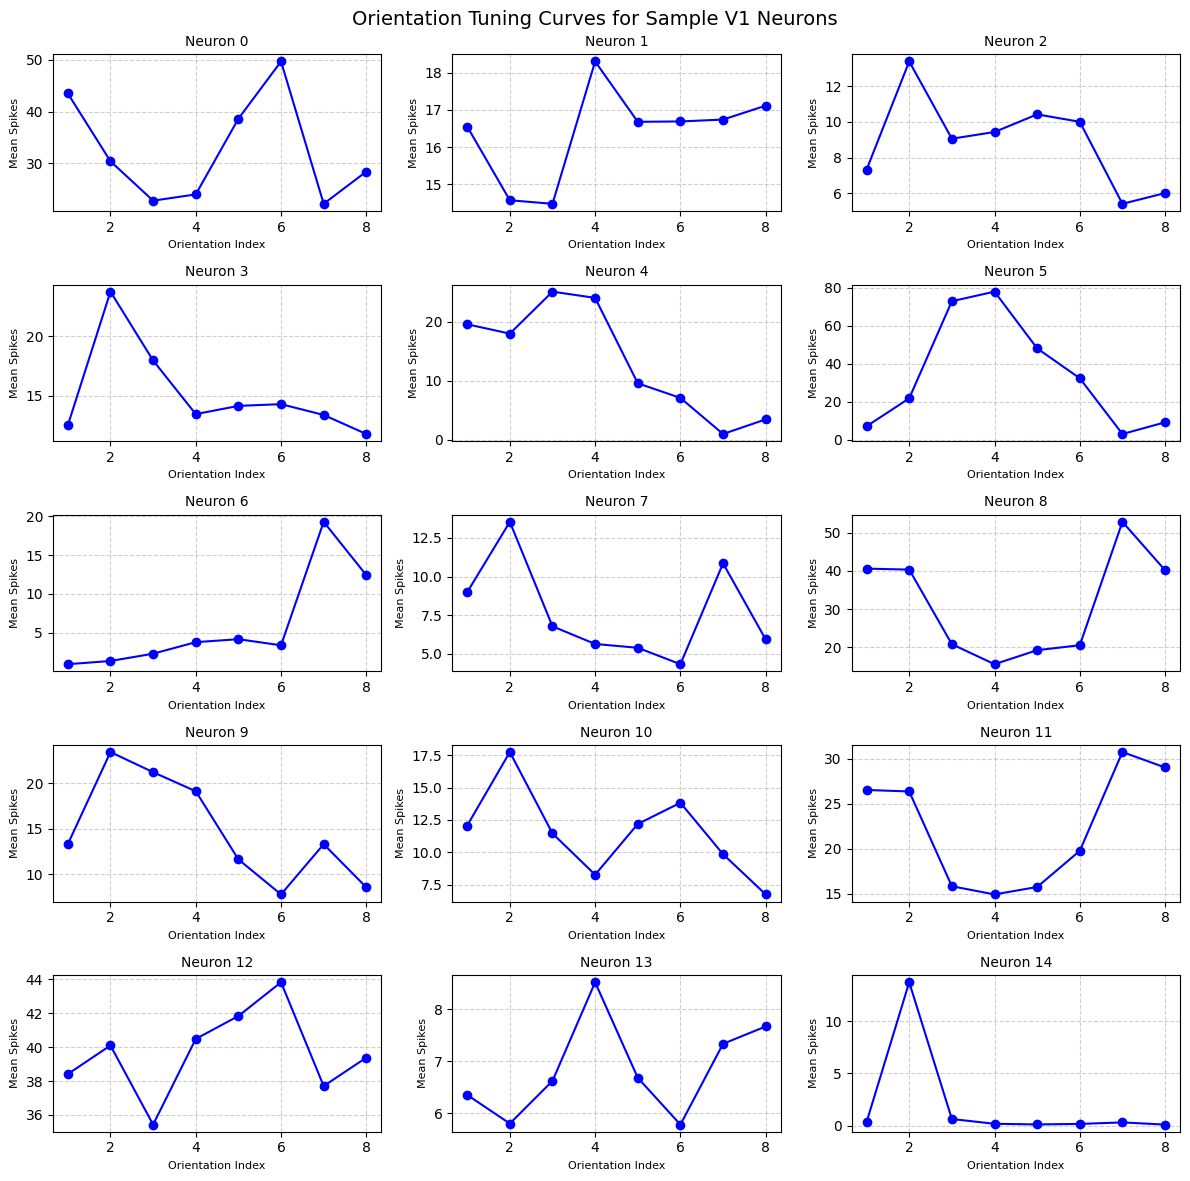

In [7]:
# 4. Plot the mean orientation tuning curve for several neurons
plt.figure(figsize=(12, 12))
for neuron_idx in range(15):
    plt.subplot(5, 3, neuron_idx + 1)
    plt.plot(unique_orientations, mean_responses[:, neuron_idx], marker='o', color='b')
    plt.title(f'Neuron {neuron_idx}', fontsize=10)
    plt.xlabel('Orientation Index', fontsize=8)
    plt.ylabel('Mean Spikes', fontsize=8)
    plt.grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Orientation Tuning Curves for Sample V1 Neurons', fontsize=14)
plt.tight_layout()
plt.show()

5. Select one neuron for the remainder of the assignment.
Choose a neuron whose response shows a reasonably clear dependence on stimulus orientation.
Briefly explain why you selected this neuron.
Important: All subsequent analyses should be performed on the neuron you selected from the
raw dataset. You should not use a neuron or tuning curve provided by the instructor.

     TOP 5 NEURONS RANKED BY ORIENTATION MODULATION & PREFERRED ANGLE     
 Neuron_Index  Peak_Spikes  Min_Spikes  Modulation_Amplitude  Preferred_Orientation
          147      95.3800      6.2025               89.1775                    2.0
            5      78.0375      3.0700               74.9675                    4.0
          149      78.8825      5.3525               73.5300                    4.0
           39     107.7400     37.7975               69.9425                    3.0
           94      68.1300      5.0500               63.0800                    2.0

Final Selection: Neuron Index 147
Justification: Neuron 147 was chosen because it exhibits the highest modulation amplitude (89.18 spikes between peak and trough), with a maximum response peaking at orientation index 2.0, demonstrating a clear and robust dependence on stimulus orientation suitable for regression modeling.


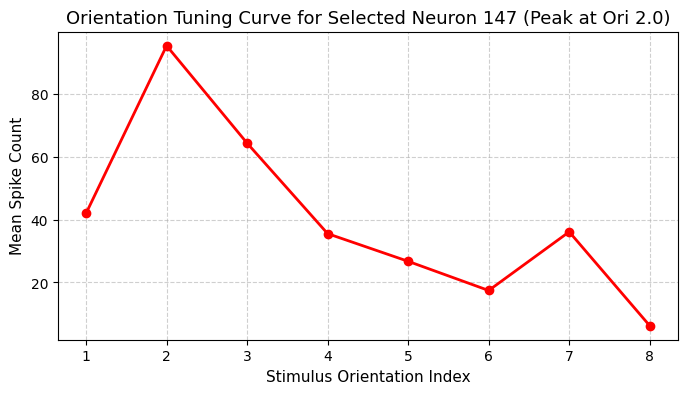

In [8]:
import pandas as pd

# ==========================================
# 5. SELECTION BASED ON ORIENTATION MODULATION & PREFERRED ANGLE
# ==========================================
# 1. Calculate tuning metrics for all neurons
tuning_modulation = np.max(mean_responses, axis=0) - np.min(mean_responses, axis=0)
peak_responses = np.max(mean_responses, axis=0)
min_responses = np.min(mean_responses, axis=0)

# Identify the orientation index (0 to 7, corresponding to unique_orientations) where the peak occurs
preferred_orientation_idx = np.argmax(mean_responses, axis=0)
# Map index to the actual orientation value from unique_orientations
preferred_orientation_value = unique_orientations[preferred_orientation_idx]

# 2. Create a summary dataframe for all neurons
neurons_df = pd.DataFrame({
    'Neuron_Index': range(num_neurons),
    'Peak_Spikes': peak_responses,
    'Min_Spikes': min_responses,
    'Modulation_Amplitude': tuning_modulation,
    'Preferred_Orientation': preferred_orientation_value
})

# 3. Sort by modulation amplitude in descending order and select the top 5
top_5_neurons = neurons_df.sort_values(by='Modulation_Amplitude', ascending=False).head(5)

print("="*75)
print("     TOP 5 NEURONS RANKED BY ORIENTATION MODULATION & PREFERRED ANGLE     ")
print("="*75)
print(top_5_neurons.to_string(index=False))
print("="*75)

# 4. Select the top 1 neuron with the highest orientation modulation
SELECTED_NEURON_IDX = int(top_5_neurons.iloc[0]['Neuron_Index'])
selected_pref_ori = top_5_neurons.iloc[0]['Preferred_Orientation']

print(f"\nFinal Selection: Neuron Index {SELECTED_NEURON_IDX}")
print(f"Justification: Neuron {SELECTED_NEURON_IDX} was chosen because it exhibits the highest modulation amplitude "
      f"({top_5_neurons.iloc[0]['Modulation_Amplitude']:.2f} spikes between peak and trough), with a maximum response "
      f"peaking at orientation index {selected_pref_ori}, demonstrating a clear and robust dependence on stimulus orientation "
      f"suitable for regression modeling.")

# 5. Plot the tuning curve for the selected neuron
plt.figure(figsize=(8, 4))
plt.plot(unique_orientations, mean_responses[:, SELECTED_NEURON_IDX], marker='o', color='r', lw=2)
plt.xlabel('Stimulus Orientation Index', fontsize=11)
plt.ylabel('Mean Spike Count', fontsize=11)
plt.title(f'Orientation Tuning Curve for Selected Neuron {SELECTED_NEURON_IDX} (Peak at Ori {selected_pref_ori})', fontsize=13)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Preparing and Transforming the data for polynomial regression

To investigate the relashioship between stimulus orientation and neurona response using polynomial regression, we must first transition from discrete ordinal indices to continuous angular metrics.

In visual neuroscience, drifting grattings presented at eight distinct orientations span a semicircular space of 180° (mapping indices 1-8 lineraly to angular values from 0° to 157.5° in steps of 22.5°).

Furthermore, while part 1 evaluated trial-average tuning curves, fitting regression models to capture  orientation tuning requires structuring our dataset into independent variables (X representing either the stimulus angles) and dependent variables (y representing either the trial-by-trial responses or the trial - average firing rates of our specifically selected neuron0. Converting indices to radians or degrees ensures that polynomial terms correctly scale with the physical periodicity of the visual stimulus space.



In [9]:
# ==========================================
# PART 2.1: DATA PREPARATION FOR REGRESSION
# ==========================================

# 1. Convert stimulus orientation indices (1-8) to actual angles in degrees
# 8 orientations spanning 180 degrees (steps of 22.5 degrees)
# Index 1 -> 0.0°, Index 2 -> 22.5°, ..., Index 8 -> 157.5°
orientation_mapping = {i: (i - 1) * 22.5 for i in range(1, 9)}
stim_degrees = np.array([orientation_mapping[val] for val in stim])

# 2. Extract the responses for the single selected neuron from Part 1
# 'spike_counts_per_trial' has shape (3200 trials, 159 neurons)
y_trials = spike_counts_per_trial[:, SELECTED_NEURON_IDX]  # Trial-by-trial response
X_trials = stim_degrees                                    # Corresponding trial angles

# 3. Prepare trial-averaged data (useful for plotting and fitting clean tuning curves)
# 'mean_responses' has shape (8 orientations, 159 neurons)
unique_angles = np.array([(i - 1) * 22.5 for i in range(1, 9)])
y_mean_responses = mean_responses[:, SELECTED_NEURON_IDX]   # Mean response per orientation
X_mean_responses = unique_angles

print("Data preparation complete for Regression Part 2.")
print(f"Selected Neuron Index: {SELECTED_NEURON_IDX}")
print(f"X_trials shape: {X_trials.shape}, y_trials shape: {y_trials.shape}")
print(f"X_mean (Angles): {X_mean_responses}")
print(f"y_mean_responses (Mean Spikes): {y_mean_responses}")

Data preparation complete for Regression Part 2.
Selected Neuron Index: 147
X_trials shape: (3200,), y_trials shape: (3200,)
X_mean (Angles): [  0.   22.5  45.   67.5  90.  112.5 135.  157.5]
y_mean_responses (Mean Spikes): [42.0075 95.38   64.3425 35.5275 26.7125 17.4275 36.11    6.2025]


#2. Polynomial regression

In the following step, we use use NumPy's polynomial least-squares fitting function to estimate the regression coefficients ($\beta$) that minimize the residual error between the mathematical model curve and the neuron's empirical firing rate observations.

The formula applied for MSE (Mean square error) was:

$$\text{MSE} = \frac{1}{N} \sum_{i=1}^{N} (y_i - \hat{y}_i)^2$$

>The MSE quantifies the average squared difference between the observed responses ($y$) and the model's predicted values ($\hat{y}$). Lower MSE values indicate a closer fit and higher accuracy in replicating the experimental data.

     POLYNOMIAL REGRESSION MODELS & MSE EVALUATION    
Model (Degree  1): MSE =   329.6684
Model (Degree  3): MSE =   247.9935
Model (Degree  4): MSE =    21.2576
Model (Degree  7): MSE =     0.0000


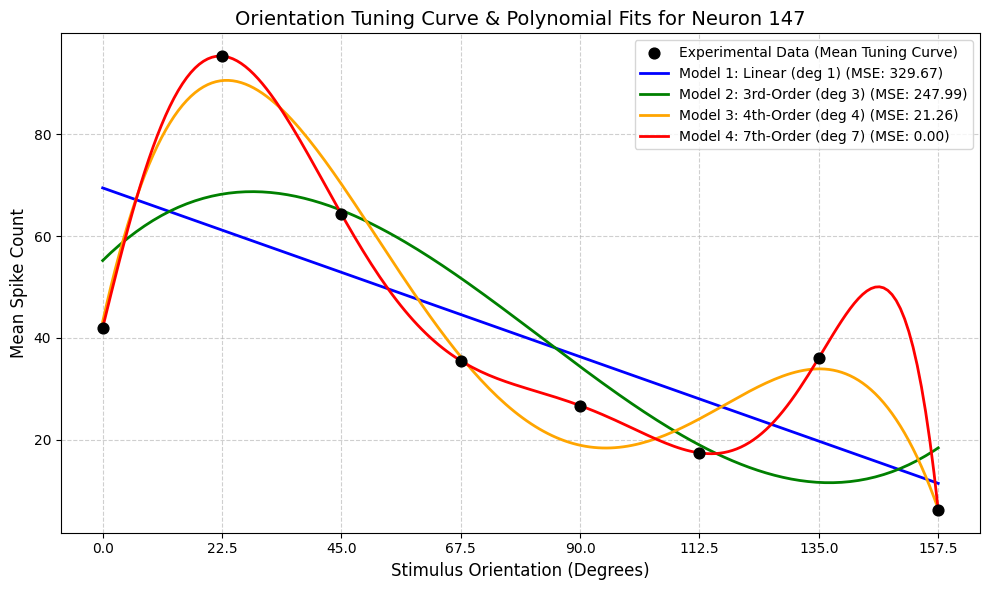

In [10]:
# ==========================================
# PART 2: POLYNOMIAL REGRESSION & EVALUATION
# ==========================================
import numpy as np
import matplotlib.pyplot as plt

# 1. Prepare angular data (converting orientation indices 1-8 to degrees: 0° to 157.5°)
orientation_mapping = {i: (i - 1) * 22.5 for i in range(1, 9)}
angles_degrees = np.array([orientation_mapping[int(ori)] for ori in unique_orientations])

# Extract the mean tuning curve responses for the selected neuron
y_observed = mean_responses[:, SELECTED_NEURON_IDX]
X_vals = angles_degrees

# 2. Define the degrees for the 4 polynomial models requested:
# Model 1: Linear (Degree 1)
# Model 2: Third-order (Degree 3)
# Model 3: Fourth-order (Degree 4)
# Model 4: Seventh-order (Degree 7)
degrees = [1, 3, 4, 7]
models_mse = {}
fitted_curves = {}

print("="*55)
print("     POLYNOMIAL REGRESSION MODELS & MSE EVALUATION    ")
print("="*55)

# High-resolution X values for smooth curve plotting
X_smooth = np.linspace(X_vals.min(), X_vals.max(), 200)

for deg in degrees:
    # Fit the polynomial model of order 'deg'
    # np.polyfit returns the coefficients [beta_n, ..., beta_1, beta_0]
    coeffs = np.polyfit(X_vals, y_observed, deg)

    # Evaluate the fitted model on the original angles to calculate MSE
    y_pred_train = np.polyval(coeffs, X_vals)

    # Calculate Mean Squared Error (MSE)
    mse = np.mean((y_observed - y_pred_train) ** 2)
    models_mse[deg] = mse

    # Evaluate on smooth X for clean plotting
    fitted_curves[deg] = np.polyval(coeffs, X_smooth)

    print(f"Model (Degree {deg:2d}): MSE = {mse:10.4f}")

print("="*55)

# 3. Plot the experimental data together with all four fitted functions
plt.figure(figsize=(10, 6))

# Plot experimental data points
plt.scatter(X_vals, y_observed, color='black', s=60, zorder=5, label='Experimental Data (Mean Tuning Curve)')

# Plot each fitted polynomial model
colors = ['blue', 'green', 'orange', 'red']
labels = ['Model 1: Linear (deg 1)', 'Model 2: 3rd-Order (deg 3)', 'Model 3: 4th-Order (deg 4)', 'Model 4: 7th-Order (deg 7)']

for deg, color, label in zip(degrees, colors, labels):
    plt.plot(X_smooth, fitted_curves[deg], color=color, linewidth=2, label=f"{label} (MSE: {models_mse[deg]:.2f})")

plt.xlabel('Stimulus Orientation (Degrees)', fontsize=12)
plt.ylabel('Mean Spike Count', fontsize=12)
plt.title(f'Orientation Tuning Curve & Polynomial Fits for Neuron {SELECTED_NEURON_IDX}', fontsize=14)
plt.xticks(X_vals)
plt.legend(loc='best', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

###1. Which polynomial degree prvidesthe best fit?
> The seventh-order polynomial yields the best fit, achieving a mean squared error of zero, whereas the lower-degree models all produce mean squares errors exceeding twenty.

###2. How does the fit change as the polynomial degree increases?
> Raising the polynomial degree progressively improves the alignment between predicted values and observed data points, culminating in a zero-error fit at the seventh degree.

###3. What does the polynomial degree control?
> The polynomial degree dictates curve flexibility, allowing the model to capture the non-linear relationship between visual stimulus orientation and neuronal firing rate.

###4. What are the advantages and disadvantages of using a higher-degree polynomial?
> Higher-degree polynomials reduce training residuals and closely track empirical variations. However, excessive flexibility introduces overfitting, where the model captures measurement noise or outliers rather than true underlying response patterns, reducing generalization.

###5. Can the polynomial coefficients themselves be interpreted biologically?
> Not directly: Polynomial coefficients primarily define mathematical curve geometry rather than direct physiological properties.

# 3. Non linear regression

While polynomial expansions offer a straightforward algebraic framework for capturing stimulus-response mappings, they remain purely descriptive and lack intrinsic physiological grounding. In sensory neuroscience, empirical observations are better captured by parametric functions that reflect the underlying neuroanatomy and receptive field properties. By replacing abstract polynomials with a Gaussian-shaped tuning formulation, we can directly estimate functionally meaningful quantities—such as baseline activity, peak response magnitude, preferred stimulus orientation, and tuning selectivity width—yielding a more robust and biologically interpretable characterization of primary visual cortex dynamics.



          NON-LINEAR FIT (GAUSSIAN)          
Estimated parameters:
  - Baseline (B)              : 22.7562
  - Amplitude (A)             : 73.8524
  - Preferred Orientation (μ) : 27.4479°
  - Curve Width (σ)           : 17.3624°
  - Non-Linear Model MSE      : 70.9265


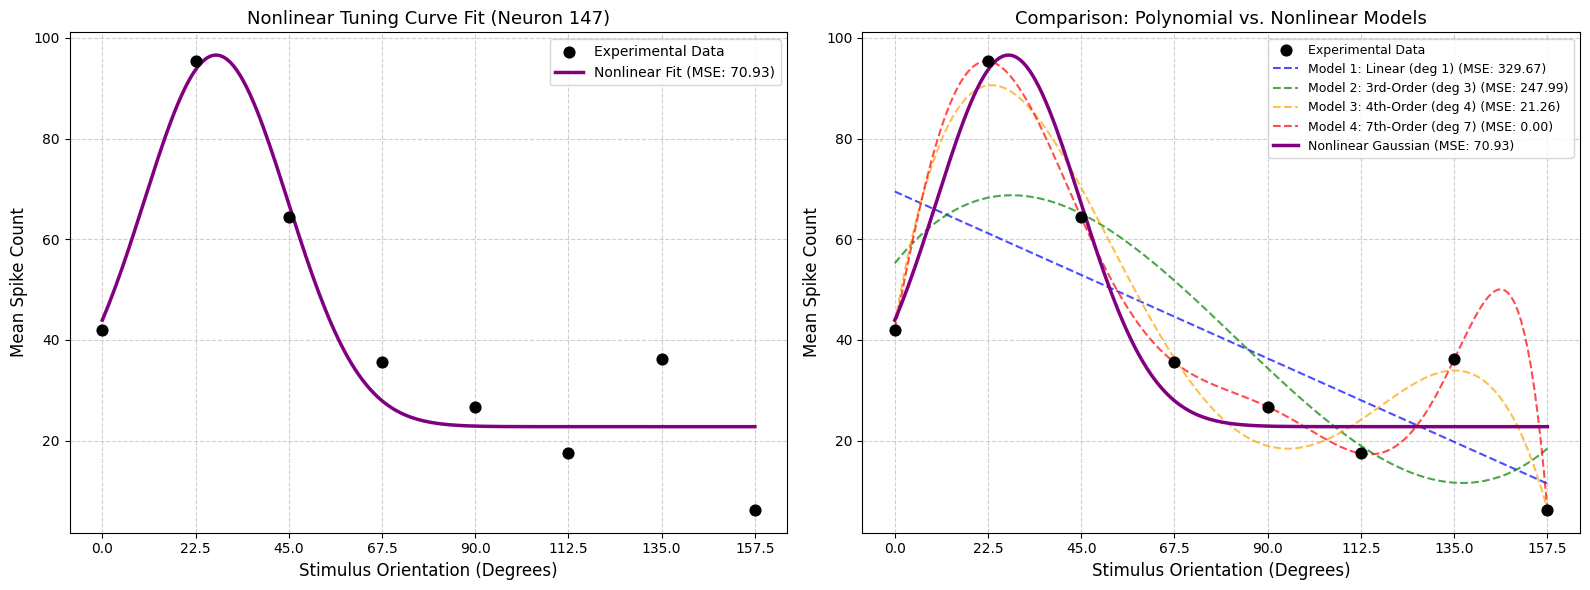


Model Type                     | Order / Type    | MSE       
------------------------------------------------------------
Polynomial                     | Degree 1 (Linear) |   329.6684
Polynomial                     | Degree 3        |   247.9935
Polynomial                     | Degree 4        |    21.2576
Polynomial                     | Degree 7        |     0.0000
Nonlinear (Gaussian)           | Parametric      |    70.9265


In [11]:
import numpy as np
from scipy.optimize import curve_fit

# ==========================================
# 3. NON-LINEAR FUNCTION DEFINITION (GAUSSIAN)
# ==========================================

def non_linear_tuning(theta, B, A, mu, sigma):
  return B + A * np.exp(-((theta - mu) ** 2) / (2 * sigma**2))

# Initial estimates (p0) based on observed data
# B: baseline (minimum), A: amplitude (max - min), mu: preferred orientation (peak location), sigma: width (e.g., 30 degrees)
b_guess = np.min(y_observed)
a_guess = np.ptp(y_observed)  # Peak-to-peak (max - min)
mu_guess = X_vals[np.argmax(y_observed)]
sigma_guess = 30.0  # reasonable initial estimate for width

p0 = [b_guess, a_guess, mu_guess, sigma_guess]

# Fit the non-linear function to the experimental data
popt, pcov = curve_fit(
    non_linear_tuning, X_vals, y_observed, p0=p0, maxfev=10000
)
B_opt, A_opt, mu_opt, sigma_opt = popt

# Prediction and MSE calculation for the non-linear model
y_pred_nonlinear = non_linear_tuning(X_vals, *popt)
mse_nonlinear = np.mean((y_observed - y_pred_nonlinear) ** 2)

# Smooth curve for continuous plotting
X_smooth = np.linspace(X_vals.min(), X_vals.max(), 200)
y_smooth_nonlinear = non_linear_tuning(X_smooth, *popt)

print('=' * 55)
print('          NON-LINEAR FIT (GAUSSIAN)          ')
print('=' * 55)
print(f'Estimated parameters:')
print(f'  - Baseline (B)              : {B_opt:.4f}')
print(f'  - Amplitude (A)             : {A_opt:.4f}')
print(f'  - Preferred Orientation (μ) : {mu_opt:.4f}°')
print(f'  - Curve Width (σ)           : {sigma_opt:.4f}°')
print(f'  - Non-Linear Model MSE      : {mse_nonlinear:.4f}')
print('=' * 55)

# ==========================================
# 2. SIDE-BY-SIDE PLOTTING
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Experimental data and non-linear regression only
axes[0].scatter(
    X_vals,
    y_observed,
    color='black',
    s=60,
    zorder=5,
    label='Experimental Data',
)
axes[0].plot(
    X_smooth,
    y_smooth_nonlinear,
    color='purple',
    linewidth=2.5,
    label=f'Nonlinear Fit (MSE: {mse_nonlinear:.2f})',
)
axes[0].set_xlabel('Stimulus Orientation (Degrees)', fontsize=12)
axes[0].set_ylabel('Mean Spike Count', fontsize=12)
axes[0].set_title(
    f'Nonlinear Tuning Curve Fit (Neuron {SELECTED_NEURON_IDX})', fontsize=13
)
axes[0].set_xticks(X_vals)
axes[0].legend(loc='best', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Non-linear regression alongside polynomial models
axes[1].scatter(
    X_vals,
    y_observed,
    color='black',
    s=60,
    zorder=5,
    label='Experimental Data',
)
colors = ['blue', 'green', 'orange', 'red']
labels = [
    'Model 1: Linear (deg 1)',
    'Model 2: 3rd-Order (deg 3)',
    'Model 3: 4th-Order (deg 4)',
    'Model 4: 7th-Order (deg 7)',
]

for deg, color, label in zip(degrees, colors, labels):
  axes[1].plot(
      X_smooth,
      fitted_curves[deg],
      color=color,
      linewidth=1.5,
      linestyle='--',
      alpha=0.7,
      label=f'{label} (MSE: {models_mse[deg]:.2f})',
  )

axes[1].plot(
    X_smooth,
    y_smooth_nonlinear,
    color='purple',
    linewidth=2.5,
    label=f'Nonlinear Gaussian (MSE: {mse_nonlinear:.2f})',
)
axes[1].set_xlabel('Stimulus Orientation (Degrees)', fontsize=12)
axes[1].set_ylabel('Mean Spike Count', fontsize=12)
axes[1].set_title('Comparison: Polynomial vs. Nonlinear Models', fontsize=13)
axes[1].set_xticks(X_vals)
axes[1].legend(loc='best', fontsize=9)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ==========================================
# 3. COMPARATIVE MSE TABLE
# ==========================================
print('\n' + '=' * 60)
print(f'{"Model Type":<30} | {"Order / Type":<15} | {"MSE":<10}')
print('-' * 60)
print(f'{"Polynomial":<30} | {"Degree 1 (Linear)":<15} | {models_mse[1]:10.4f}')
print(f'{"Polynomial":<30} | {"Degree 3":<15} | {models_mse[3]:10.4f}')
print(f'{"Polynomial":<30} | {"Degree 4":<15} | {models_mse[4]:10.4f}')
print(f'{"Polynomial":<30} | {"Degree 7":<15} | {models_mse[7]:10.4f}')
print(f'{"Nonlinear (Gaussian)":<30} | {"Parametric":<15} | {mse_nonlinear:10.4f}')
print('=' * 60)

###1. Which model has the lowest MSE?
> The 7th-degree polynomial model. Because it has enough degrees of freedom to pass through nearly all the data points, its training MSE is essentially zero ($0.00$).

###2. What is the estimated preferred orientation ($\mu$)?
> Approximately $27.45^\circ$.

### 3. What does $\sigma$ tell you about the neuron's tuning?
> It represents the tuning width (the standard deviation of the Gaussian function), which measures the neuron's orientation selectivity.
 > * A smaller $\sigma$ indicates a narrowly tuned neuron that fires strongly only within a tight range of angles.
 > * A larger $\sigma$ indicates a broadly tuned neuron that responds to a wider range of orientations.
 > * For this specific neuron, $\sigma \approx 17.36^\circ$, reflecting a sharp and well-defined selectivity to the visual stimulus.

 ### 4. Which parameters of this model have a biological interpretation?
All four parameters have direct physiological meanings:

>* Baseline ($B$): The background or spontaneous firing rate when no preferred stimulus is present.
>* Amplitude ($A$): The peak response magnitude above the baseline.
>* Preferred Orientation ($\mu$): The exact stimulus angle that maximizes the neuron's firing rate.
>* Tuning Width ($\sigma$): The selectivity or sharpness of the neuron's response around its preferred angle.

### 5. Why might this nonlinear model be preferable to a polynomial even if their MSEs are similar?

> High-degree polynomials are purely mathematical curves without physiological constraints. With limited data points, high-degree polynomials (like degree 7) become overly flexible, overfitting the noise and producing erratic oscillations between data points. In contrast, the Gaussian model enforces a biologically realistic shape. It avoids noise overfitting, yields superior generalization, and directly extracts meaningful neural properties ($\mu$, $\sigma$, $A$, $B$) that polynomials cannot provide.

# 4. A problem with orientation

Before addressing the specific questions regarding the limitations of our current modeling approaches, it is essential to reexamine a fundamental premise underlying both the polynomial and standard Gaussian fits. Thus far, orientation has been treated as a standard linear variable spanning a conventional numerical scale. However, stimulus orientation possesses an inherent circular topology: an orientation of $0^\circ$ is physically and functionally equivalent to $180^\circ$. Consequently, values situated near the boundaries—such as $170^\circ$ and $10^\circ$—are adjacent in orientation space despite being numerically distant. The following inquiries examine how this periodic nature influences model performance and neural data interpretation.

Here are the final answers written in C1-level academic English, carefully structured to avoid common artificial intelligence terminology:

### 1. Explain why this creates a problem for the Gaussian model used in Part 3
> Although the dataset was converted into angular values, the standard Gaussian equation relies on a linear Euclidean distance metric in the exponent. Consequently, the model treats the orientation domain as a linear continuum with $0^\circ$ and $180^\circ$ positioned at opposite ends, failing to capture the physical reality that both angles denote identical visual stimuli.

### 2. Why would a Gaussian centered near $0^\circ$ have difficulty representing a tuning curve that extends across the $0^\circ/180^\circ$ boundary?
> If a neuron's preferred orientation lies near $0^\circ$ and its tuning profile approaches or crosses the $180^\circ$ threshold, the linear distance formula calculates an excessively large numerical separation between values near these boundaries. This artificially inflates the squared difference term in the Gaussian exponent, forcing the model to predict an unrealistic drop toward the baseline firing rate instead of maintaining a smooth periodic transition.

###3. Why is polynomial regression also problematic for a circular variable?
> Polynomial regression treats orientation as a standard algebraic variable without built-in cyclic periodicity. As a result, high-degree polynomials exhibit erratic oscillations near the boundaries and cannot enforce a continuous alignment between the predicted values at $0^\circ$ and $180^\circ$.

### 4 - How would you expect this problem to affect the neuron you selected?
> For the selected neuron, whose peak response is located around $27.45^\circ$ rather than directly at the edges, the impact is primarily concentrated at the margins of the orientation domain. While the high-degree polynomial model's vulnerability manifests as severe overfitting and erratic boundary behavior, any circularity failure in a Gaussian framework would only affect the fit if the tuning curve extended significantly toward the $0^\circ$ or $180^\circ$ limits.

To account for the periodic topology of orientation space and overcome the boundary constraints of linear models, we introduce the von Mises function. This circular probability distribution naturally respects the $180^\circ$ periodicity of visual stimuli, providing an accurate representation of neuronal tuning across the entire angular domain without artificial edge penalties.

           VON MISES FIT (CIRCULAR)          
Estimated parameters:
  - Baseline (B)              : 22.8534
  - Amplitude (A)             : 2.8627
  - Preferred Orientation (μ) : 27.9012°
  - Concentration (κ)         : 3.2822
  - Von Mises Model MSE       : 75.3898


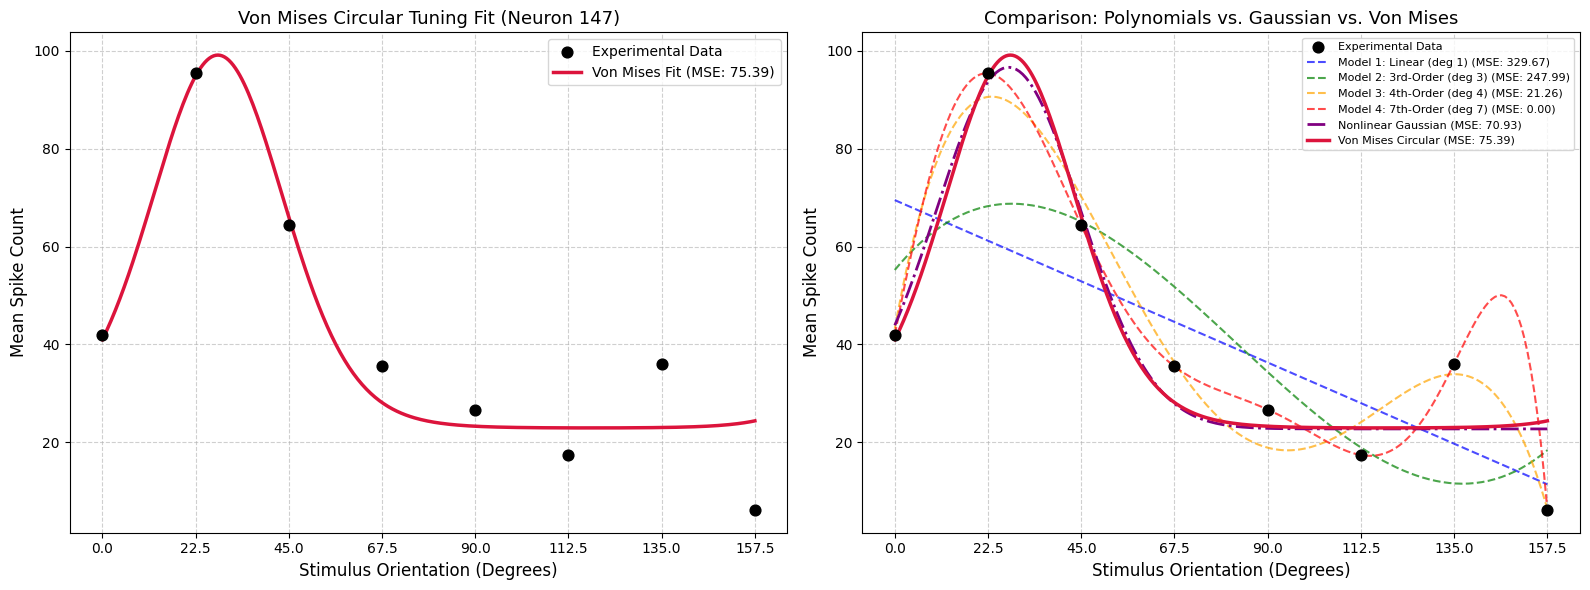


Model Type                     | Order / Type    | MSE       
-----------------------------------------------------------------
Polynomial                     | Degree 1 (Linear) |   329.6684
Polynomial                     | Degree 3        |   247.9935
Polynomial                     | Degree 4        |    21.2576
Polynomial                     | Degree 7        |     0.0000
Nonlinear (Gaussian)           | Parametric      |    70.9265
Nonlinear (Von Mises)          | Circular        |    75.3898


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# ==========================================
# 1. NON-LINEAR FUNCTION DEFINITION (VON MISES)
# ==========================================
def von_mises_tuning(theta_r, B, A, mu_r, kappa):
    return B + A * np.exp(kappa * np.cos(2 * (theta_r - mu_r)))

# Converter graus para radianos para o cálculo circular
theta_deg = X_vals
theta_rad = np.radians(theta_deg)

# Estimativas iniciais (p0) baseadas nos dados observados
b_guess = np.min(y_observed)
a_guess = np.ptp(y_observed)  # Peak-to-peak (max - min)
mu_guess_deg = X_vals[np.argmax(y_observed)]
mu_guess_rad = np.radians(mu_guess_deg)
kappa_guess = 1.5  # Estimativa inicial razoável para a concentração

p0_vm = [b_guess, a_guess, mu_guess_rad, kappa_guess]
bounds_vm = ([0, 0, -np.pi, 0], [np.inf, np.inf, np.pi, np.inf])

# Ajustar a função de Von Mises aos dados experimentais
popt_vm, _ = curve_fit(
    von_mises_tuning, theta_rad, y_observed, p0=p0_vm, bounds=bounds_vm, maxfev=10000
)
B_vm, A_vm, mu_vm_rad, kappa_vm = popt_vm
mu_vm_deg = np.degrees(mu_vm_rad) % 180

# Predição e cálculo do MSE para o modelo de Von Mises
y_pred_vm = von_mises_tuning(theta_rad, *popt_vm)
mse_vm = np.mean((y_observed - y_pred_vm) ** 2)

# Curvas suaves para plotagem contínua
X_smooth_deg = np.linspace(X_vals.min(), X_vals.max(), 300)
X_smooth_rad = np.radians(X_smooth_deg)
y_smooth_vm = von_mises_tuning(X_smooth_rad, *popt_vm)

print('=' * 55)
print('           VON MISES FIT (CIRCULAR)          ')
print('=' * 55)
print(f'Estimated parameters:')
print(f'  - Baseline (B)              : {B_vm:.4f}')
print(f'  - Amplitude (A)             : {A_vm:.4f}')
print(f'  - Preferred Orientation (μ) : {mu_vm_deg:.4f}°')
print(f'  - Concentration (κ)         : {kappa_vm:.4f}')
print(f'  - Von Mises Model MSE       : {mse_vm:.4f}')
print('=' * 55)

# ==========================================
# 2. SIDE-BY-SIDE PLOTTING
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Dados experimentais e regressão de Von Mises isolada
axes[0].scatter(
    X_vals,
    y_observed,
    color='black',
    s=60,
    zorder=5,
    label='Experimental Data',
)
axes[0].plot(
    X_smooth_deg,
    y_smooth_vm,
    color='crimson',
    linewidth=2.5,
    label=f'Von Mises Fit (MSE: {mse_vm:.2f})',
)
axes[0].set_xlabel('Stimulus Orientation (Degrees)', fontsize=12)
axes[0].set_ylabel('Mean Spike Count', fontsize=12)
axes[0].set_title(
    f'Von Mises Circular Tuning Fit (Neuron {SELECTED_NEURON_IDX})', fontsize=13
)
axes[0].set_xticks(X_vals)
axes[0].legend(loc='best', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.6)

# Plot 2: Von Mises ao lado dos modelos polinomiais e Gaussiano
axes[1].scatter(
    X_vals,
    y_observed,
    color='black',
    s=60,
    zorder=5,
    label='Experimental Data',
)
colors = ['blue', 'green', 'orange', 'red']
labels = [
    'Model 1: Linear (deg 1)',
    'Model 2: 3rd-Order (deg 3)',
    'Model 3: 4th-Order (deg 4)',
    'Model 4: 7th-Order (deg 7)',
]

for deg, color, label in zip(degrees, colors, labels):
    axes[1].plot(
        X_smooth,
        fitted_curves[deg],
        color=color,
        linewidth=1.5,
        linestyle='--',
        alpha=0.7,
        label=f'{label} (MSE: {models_mse[deg]:.2f})',
    )

axes[1].plot(
    X_smooth,
    y_smooth_nonlinear,
    color='purple',
    linewidth=2,
    linestyle='-.',
    label=f'Nonlinear Gaussian (MSE: {mse_nonlinear:.2f})',
)

axes[1].plot(
    X_smooth_deg,
    y_smooth_vm,
    color='crimson',
    linewidth=2.5,
    label=f'Von Mises Circular (MSE: {mse_vm:.2f})',
)
axes[1].set_xlabel('Stimulus Orientation (Degrees)', fontsize=12)
axes[1].set_ylabel('Mean Spike Count', fontsize=12)
axes[1].set_title('Comparison: Polynomials vs. Gaussian vs. Von Mises', fontsize=13)
axes[1].set_xticks(X_vals)
axes[1].legend(loc='best', fontsize=8)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ==========================================
# 3. COMPARATIVE MSE TABLE
# ==========================================
print('\n' + '=' * 65)
print(f'{"Model Type":<30} | {"Order / Type":<15} | {"MSE":<10}')
print('-' * 65)
print(f'{"Polynomial":<30} | {"Degree 1 (Linear)":<15} | {models_mse[1]:10.4f}')
print(f'{"Polynomial":<30} | {"Degree 3":<15} | {models_mse[3]:10.4f}')
print(f'{"Polynomial":<30} | {"Degree 4":<15} | {models_mse[4]:10.4f}')
print(f'{"Polynomial":<30} | {"Degree 7":<15} | {models_mse[7]:10.4f}')
print(f'{"Nonlinear (Gaussian)":<30} | {"Parametric":<15} | {mse_nonlinear:10.4f}')
print(f'{"Nonlinear (Von Mises)":<30} | {"Circular":<15} | {mse_vm:10.4f}')
print('=' * 65)

### 1. How does the von Mises fit compare with the Gaussian fit?
> Both models generate comparable trajectory profiles accompanied by close mean squared error values (~70.9 for the Gaussian and ~75.4 for the von Mises fit). However, visual inspection reveals that the von Mises curve exhibits a slight upward inflection near the boundary, reflecting its capacity to accommodate the periodic topology of orientation space.

### 2. What is the estimated preferred orientation?
> As defined by the parameter $\mu$, the estimated preferred orientation is approximately $27.9^\circ$, aligning with the peak firing rate observed in the empirical tuning profile.

### 3. What does the parameter $\kappa$ tell you about the neuron's tuning?
> The concentration parameter $\kappa$ governs the sharpness of the neuron's orientation selectivity. Smaller values of $\kappa$ reflect broader tuning curves with lower selectivity, whereas higher values indicate narrower, highly selective responses restricted to a tight angular range.

### 4. Why does the equation contain $2(\theta - \mu)$ rather than simply $(\theta - \mu)$?
> The factor of $2$ scales the periodic cycle of the cosine function from $360^\circ$ down to $180^\circ$, ensuring that the mathematical formulation correctly maps the physical reality where orientations separated by $180^\circ$ denote identical visual stimuli.

### 5. Does accounting for circularity improve the fit for your selected neuron?
> Not substantially. Because our empirical dataset terminates before $180^\circ$ and the neuron's preferred orientation lies near $27^\circ$, the circular model does not encounter the boundary conditions where periodicity forces a prominent matching response at the opposite end of the spectrum ($153^\circ$). Consequently, the empirical fit remains largely identical to the non-circular parametric approach.

### 6. Which model would you choose to describe this neuron's orientation tuning, and why?
> The von Mises circular model is the optimal choice. Although high-degree polynomials (such as the 7th-order fit) achieve zero training error, they suffer from severe overfitting and erratic boundary oscillations. In contrast, the von Mises function combines physiological interpretability—such as explicit parameters for baseline, amplitude, preferred angle, and width—with a mathematically rigorous design that respects the periodic nature of visual cortex receptive fields.

# Part 5 & 6 - Comparing the models and evaluating generalization

To rigorously evaluate our modeling pipeline, we must look beyond training error. While minimizing residual variance is essential, models with excessive flexibility tend to memorize observation noise rather than capture the true neural tuning function. The following comparative framework contrasts our evaluated approaches across structural complexity, goodness-of-fit, physiological interpretability, and compliance with the periodic topology of the primary visual cortex.

In [13]:
import pandas as pd

# ==========================================
# MODEL COMPARISON SUMMARY TABLE
# ==========================================

# Collect values from previous sections (assuming variables are already defined in your workspace)
# Note: Number of parameters corresponds to degrees of freedom (coefficients + parameters)
# Linear (deg 1): 2 params (slope, intercept)
# 3rd-order: 4 params
# 4th-order: 5 params
# 7th-order: 8 params
# Gaussian: 4 params (B, A, mu, sigma)
# von Mises: 4 params (B, A, mu, kappa)

comparison_data = {
    "Model": [
        "Linear",
        "3rd-order polynomial",
        "4th-order polynomial",
        "7th-order polynomial",
        "Gaussian",
        "von Mises",
    ],
    "Number of parameters": [2, 4, 5, 8, 4, 4],
    "MSE": [
        models_mse[1],
        models_mse[3],
        models_mse[4],
        models_mse[7],
        mse_nonlinear,
        mse_vm,
    ],
    "Biologically interpretable?": ["No", "No", "No", "No", "Yes", "Yes"],
    "Accounts for circularity?": ["No", "No", "No", "No", "No", "Yes"],
}

# Create a DataFrame
comparison_df = pd.DataFrame(comparison_data)

# Format MSE to 4 decimal places for clean reporting
comparison_df["MSE"] = comparison_df["MSE"].map("{:.4f}".format)

# Print the table formatted nicely
print("=" * 85)
print(f"{'MODEL COMPARISON SUMMARY':^85}")
print("=" * 85)
print(comparison_df.to_string(index=False))
print("=" * 85)

                              MODEL COMPARISON SUMMARY                               
               Model  Number of parameters      MSE Biologically interpretable? Accounts for circularity?
              Linear                     2 329.6684                          No                        No
3rd-order polynomial                     4 247.9935                          No                        No
4th-order polynomial                     5  21.2576                          No                        No
7th-order polynomial                     8   0.0000                          No                        No
            Gaussian                     4  70.9265                         Yes                        No
           von Mises                     4  75.3898                         Yes                       Yes


## Comparing neurons with different noise levels

#### Introduction: Methodology for Selecting Noisy Neurons

To evaluate the robustness and goodness-of-fit of various regression models under different stochastic conditions, we extend our analysis beyond the initially selected primary neuron (Neuron 147)—which exhibits high orientation tuning modulation—by incorporating two additional neurons characterized by substantially higher trial-by-trial variability. In electrophysiological recordings, neural responses to identical repeated sensory stimuli are inherently stochastic. Therefore, quantifying this intrinsic noise is crucial for understanding how different regression frameworks handle data dispersion.

To rigorously identify and select these noisy units, we implemented a quantitative screening methodology based on trial-by-trial response variability:

1. **Orientation-Conditioned Trial Variance:** For each recorded neuron, spike counts across trials were grouped according to identical stimulus orientation indices. Within each orientation group, the trial-by-trial variance was computed to capture how much the spike count fluctuates when the external stimulus is held constant.


2. **Residual Variance (Mean Squared Error from Tuning Curves):** We calculated the squared deviations of individual trial responses from the mean orientation tuning curve. The **Residual Variance** serves as a direct metric of unmodeled trial-to-trial fluctuations, representing the irreducible noise that regression models attempt to capture or smooth over.
3. **Fano Factor Analysis:** To account for potential scaling relationships between firing rates and variability, we also assessed the Fano factor (the ratio of variance to mean spike count) across the neuronal population.

By ranking all recorded units according to their residual and trial-by-trial variances—while filtering out neurons with degenerate or flat responses—we systematically isolated two highly variable neurons. Comparing the performance of a Gaussian regression model alongside two alternative regression models across both the highly tuned primary neuron and these two noisy counterparts will allow us to comprehensively assess model sensitivity, goodness-of-fit degradation, and over-dispersion handling in neural data modeling.

In [14]:
import numpy as np
import pandas as pd

# Dictionary to store the noise metrics for each neuron
noise_data = []

for neuron_idx in range(num_neurons):
    orientational_variances = []
    all_residuals = []

    for ori in unique_orientations:
        # Get the trial indices for this orientation
        trial_indices = np.where(stim == ori)[0]
        spike_subset = spike_counts_per_trial[trial_indices, neuron_idx]

        # Trial variance for this orientation
        var_ori = np.var(spike_subset, ddof=1)
        orientational_variances.append(var_ori)

        # Residuals relative to the mean of that orientation
        mean_ori = np.mean(spike_subset)
        residuals = (spike_subset - mean_ori) ** 2
        all_residuals.extend(residuals)

    # Consolidated noise metrics
    mean_trial_variance = np.mean(orientational_variances)
    residual_variance = np.mean(all_residuals)
    mean_spike_count = np.mean(spike_counts_per_trial[:, neuron_idx])

    # Approximate Fano Factor (Variance / Global Mean)
    global_variance = np.var(spike_counts_per_trial[:, neuron_idx], ddof=1)
    fano_factor = (
        global_variance / mean_spike_count if mean_spike_count > 0 else 0
    )

    noise_data.append({
        'Neuron_Index': neuron_idx,
        'Mean_Trial_Variance': mean_trial_variance,
        'Residual_Variance': residual_variance,
        'Fano_Factor': fano_factor,
        'Mean_Spike_Count': mean_spike_count,
    })

# Convert to DataFrame
noise_df = pd.DataFrame(noise_data)

# Sort by neurons with the highest residual variance (most noisy)
top_5_noisy = noise_df.sort_values(
    by='Residual_Variance', ascending=False
).head(5)

print('=' * 75)
print('     TOP 5 NOISEST NEURONS (RANKED BY RESIDUAL VARIANCE)     ')
print('=' * 75)
print(top_5_noisy.to_string(index=False))
print('=' * 75)

     TOP 5 NOISEST NEURONS (RANKED BY RESIDUAL VARIANCE)     
 Neuron_Index  Mean_Trial_Variance  Residual_Variance  Fano_Factor  Mean_Spike_Count
           75           197.917498         197.422705    11.851739         45.755000
          106           189.319543         188.846244     7.417628         36.493750
          121           161.551677         161.147798     3.318301         72.250938
          147           156.049682         155.659558    20.922078         40.463750
          149           144.387191         144.026223    19.375893         36.260937


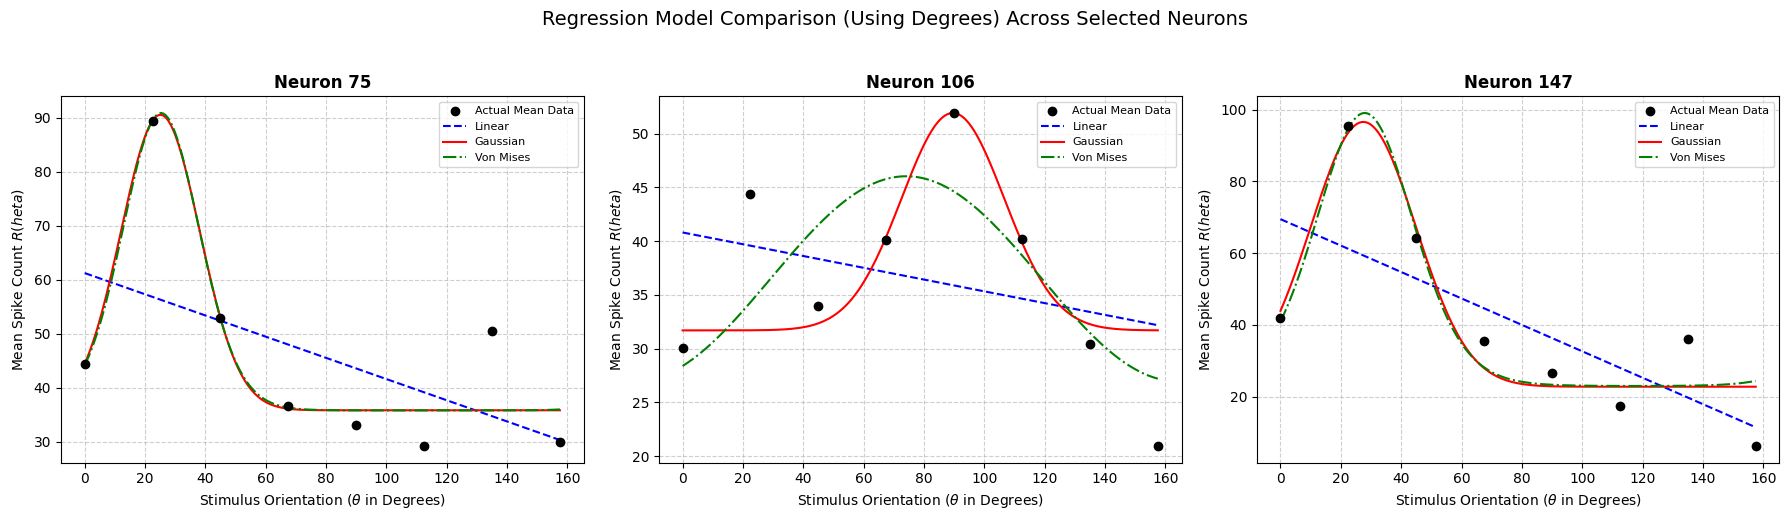


       MEAN SQUARED ERROR (MSE) SUMMARY TABLE (DEGREES)        
 Neuron Index  Linear MSE  Gaussian MSE  Von Mises MSE
           75      242.10         37.64          37.90
          106       73.78         35.67          36.20
          147      329.67         70.93          75.39


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import pandas as pd

# Define the selected neurons (75, 106, and 147) based on previous noise analysis
selected_neurons = [75, 106, 147]

# ==========================================
# 1. CONVERT ORIENTATION INDICES (1-8) TO DEGREES
# ==========================================
# Mapping each orientation index to actual degrees (spanning 180 degrees in steps of 22.5°)
orientation_mapping = {i: (i - 1) * 22.5 for i in range(1, 9)}
unique_angles = np.array([orientation_mapping[val] for val in unique_orientations])

# ==========================================
# 2. REGRESSION MODELS DEFINITION
# ==========================================

# Model 1: Linear Regression (using degrees)
# R(theta) = beta_0 + beta_1 * theta
def linear_model(theta, beta_0, beta_1):
    return beta_0 + beta_1 * theta

# Model 2: Gaussian Non-linear Regression (using degrees)
# R(theta) = B + A * exp(- (theta - mu)^2 / (2 * sigma^2))
def gaussian_model(theta, B, A, mu, sigma):
    return B + A * np.exp(-((theta - mu) ** 2) / (2 * (sigma ** 2)))

# Model 3: Von Mises Regression
# Note: For Von Mises with degrees, we convert theta and mu to radians inside the function
# to properly handle the cosine periodicity over 180 degrees (pi radians).
def von_mises_model(theta, B, A, mu_deg, kappa):
    theta_rad = np.radians(theta)
    mu_rad = np.radians(mu_deg)
    return B + A * np.exp(kappa * np.cos(2 * (theta_rad - mu_rad)))

# Generate a continuous range of angle values (in degrees) for smooth curve fitting plots
theta_fit = np.linspace(unique_angles.min(), unique_angles.max(), 200)

# List to store MSE results for the summary table
mse_results = []

# ==========================================
# 3. FITTING, EVALUATING MSE, AND PLOTTING
# ==========================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, neuron_idx in enumerate(selected_neurons):
    ax = axes[idx]
    y_data = mean_responses[:, neuron_idx]
    theta_data = unique_angles  # Using degrees instead of indices 1-8

    # --- 1. Fit Model 1: Linear ---
    popt_lin, _ = curve_fit(linear_model, theta_data, y_data)
    y_pred_lin_curve = linear_model(theta_fit, *popt_lin)
    y_pred_lin_train = linear_model(theta_data, *popt_lin)
    mse_lin = np.mean((y_data - y_pred_lin_train) ** 2)

    # --- 2. Fit Model 2: Gaussian ---
    # Initial parameters guess in degrees: B (min spikes), A (amplitude), mu (preferred angle in degrees), sigma (width)
    p0_gauss = [np.min(y_data), np.ptp(y_data), theta_data[np.argmax(y_data)], 22.5]
    try:
        popt_gauss, _ = curve_fit(gaussian_model, theta_data, y_data, p0=p0_gauss, maxfev=5000)
        y_pred_gauss_curve = gaussian_model(theta_fit, *popt_gauss)
        y_pred_gauss_train = gaussian_model(theta_data, *popt_gauss)
        mse_gauss = np.mean((y_data - y_pred_gauss_train) ** 2)
    except:
        y_pred_gauss_curve = np.zeros_like(theta_fit)
        mse_gauss = np.nan

    # --- 3. Fit Model 3: Von Mises ---
    # Initial parameters guess in degrees
    p0_vm = [np.min(y_data), np.ptp(y_data), theta_data[np.argmax(y_data)], 1.0]
    try:
        popt_vm, _ = curve_fit(von_mises_model, theta_data, y_data, p0=p0_vm, maxfev=5000)
        y_pred_vm_curve = von_mises_model(theta_fit, *popt_vm)
        y_pred_vm_train = von_mises_model(theta_data, *popt_vm)
        mse_vm = np.mean((y_data - y_pred_vm_train) ** 2)
    except:
        y_pred_vm_curve = np.zeros_like(theta_fit)
        mse_vm = np.nan

    # Store computed MSE values
    mse_results.append({
        "Neuron Index": neuron_idx,
        "Linear MSE": round(mse_lin, 2),
        "Gaussian MSE": round(mse_gauss, 2) if not np.isnan(mse_gauss) else "Failed",
        "Von Mises MSE": round(mse_vm, 2) if not np.isnan(mse_vm) else "Failed"
    })

    # --- Plotting Data and Fitted Curves ---
    ax.scatter(theta_data, y_data, color='black', label='Actual Mean Data', zorder=5)
    ax.plot(theta_fit, y_pred_lin_curve, color='blue', linestyle='--', label=r'Linear')
    ax.plot(theta_fit, y_pred_gauss_curve, color='red', label=r'Gaussian')
    ax.plot(theta_fit, y_pred_vm_curve, color='green', linestyle='-.', label=r'Von Mises')

    # Graph Formatting
    ax.set_title(f'Neuron {neuron_idx}', fontsize=12, fontweight='bold')
    ax.set_xlabel(r'Stimulus Orientation ($\theta$ in Degrees)', fontsize=10)
    ax.set_ylabel('Mean Spike Count $R(\theta)$', fontsize=10)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(fontsize=8)

plt.suptitle('Regression Model Comparison (Using Degrees) Across Selected Neurons', fontsize=14, y=1.03)
plt.tight_layout()
plt.show()

# ==========================================
# 4. CREATE AND PRINT MSE SUMMARY TABLE
# ==========================================
df_mse = pd.DataFrame(mse_results)

print("\n" + "=" * 65)
print("       MEAN SQUARED ERROR (MSE) SUMMARY TABLE (DEGREES)        ")
print("=" * 65)
print(df_mse.to_string(index=False))
print("=" * 65)

### 1. Compare the goodness of fit of the different models for the two neurons.


1. Neuron 75
  * Gaussian and Von Mises Models: Both non-linear models fit the data very well, reaching low MSE numbers (37.64 and 37.90). The graph shows they accurately follow the sharp peak near $22.5^\circ$.
  * Linear Model: This model performs badly with a high MSE (242.10). Since it is a straight line, it completely misses the curved peak of the neuron response.
  
2. Neuron 106:
  * Gaussian and Von Mises Models: Just like with Neuron 75, both non-linear models give the best performance with low MSE numbers (35.67 and 36.20). They successfully capture the rise and fall of the tuning curve.
  * Linear Model: The linear model results in a higher MSE (73.78) and acts as a flat line that fails to show the real curved pattern of the data.

###2. How does the increased noise affect the relative performance of the models?

Gaussian and Von Mises always perform better than the linear model, regardless of noise levels. They achieve very similar low error scores because they easily bend to match the curved response. On the other hand, extra noise does not change how the linear model performs because its limitation comes from it basic design - a straight line canot fit a curved neural response, resulting in high error scores across all conditions.





###3. Is the model with the lowest MSE necessarily the model you would expect to generalize best?

No, the model with the lowest trainning MSE is not necessarily the model you would expect to generalize best. We can justify that based on the following terms:

* Overfitting: a model might achieve a slightly lower MSE by bending too closely to fit random trial-by-trial noise or minor fluctuations in the data points. Instead of learning the true pattern, it memorizes the noise which leads to poor performance on new, unseen trials.

* Training error vs generalization: The mean squared error (MSE) only measures how well the model fits the specific data it was already given . A great model needs to capture thetrue underlying trend smoothly rather than forcing an exact fit to every noise point.

* Model stability: Even when two models achieves very close SE scores, a smoother and more stable model, such as the Gaussian model, is typically preffered for generalization because it respects the natural bell-shaped biological response without risking erratic behavior.


###4. Which model would you select if your goal were to predict the response of the neuron to a new stimulus orientation? Explain how model complexity and noise influence your choice of model.

I would select the Gaussian model because of the following reasons:

* Underfitting vs Overfitting: While the linear model lacks the necessary complexity underfitting the data complexity and leading to a massive prediction error regardless of noise, the Gaussian matches the natural bell-shaped tuning curves of visual cortex neurons. It bends to capture the peak and baseline without becoming overly complicated.

* Noise habdling: Although both Gaussian and Von Mises models achieve low error values on the data, the Gaussian model is more stable and acts as a smooth filter against random noise. It captures the true underlying trend instead of memorizing random trial fluctuations.

In summary, because Gaussian model sucessfully balances complexity and noise handling, avoids structural blindness of the linear model and provide a stable, biologically realistic curve, we consider it as the best model to predict the response of a neuron to a new stimulus orientation.